# From DN to reflectance, advanced: topographic correction in the Krkonoše mountains

[![Open in Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/dn_to_reflectance_pro_en.ipynb)

**OpenSkyLab · notebook for the visual** [From DN to reflectance](https://openskylab.space/edu_viz_dn_to_reflectance.html) · [česká verze](dn_to_reflectance_pro_cs.ipynb)

The advanced version of the DN-to-reflectance notebook. The TOA reflectance formula divides by the sine of the sun elevation, i.e. it assumes flat ground. In the mountains every slope gets different illumination. You compute it from a digital elevation model for two Landsat 8 scenes with different sun elevation, measure how strongly it changes forest reflectance, and compare five topographic corrections.

**Goal:** compute slope, aspect and the solar incidence angle from a DEM, measure the terrain effect on reflectance by band and season, compare the cosine, C, Minnaert and SCS+C corrections, and judge how to validate a correction fairly.

**Data:** Landsat 8 OLI Collection 1 Level-1 from the Google Cloud public archive: `LC08_L1TP_191025_20190626_20190705_01_T1` (26 June 2019, sun elevation 60°) and `LC08_L1TP_191025_20181013_20181030_01_T1` (13 Oct 2018, sun elevation 31°), bands B2–B7, BQA and MTL; Copernicus DEM GLO-30 from the AWS Open Data registry; ESA WorldCover 2021 v200 classes. A 12 × 12 km window in the eastern Krkonoše mountains, about 25 MB.

**Tasks:** five. Write your answers in the *Your answer* cells below the tasks. Lines marked `# ◀ parameter` are meant to be changed; run the cell again with Shift + Enter.

**Time:** about 70 min. You need a Google account (Colab); nothing is installed on your computer. Run the cells in order from top to bottom.

## 1. Setup and data

In [1]:
%pip install -q rasterio

Note: you may need to restart the kernel to use updated packages.


In [2]:
import requests, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.warp import reproject, Resampling
from pyproj import Transformer
warnings.filterwarnings("ignore")

In [3]:
GCS = "https://storage.googleapis.com/gcp-public-data-landsat/LC08/01/191/025/"
SCENES = {"summer": "LC08_L1TP_191025_20190626_20190705_01_T1", "autumn": "LC08_L1TP_191025_20181013_20181030_01_T1"}   # ◀ parameter: two scenes with different sun elevation
LON, LAT, SIZE = 15.70, 50.70, 12000               # ◀ parameter: window centre (Krkonoše) and its side (m)
x, y = Transformer.from_crs(4326, 32633, always_xy=True).transform(LON, LAT)
X0, Y0 = round((x - SIZE / 2) / 30) * 30, round((y - SIZE / 2) / 30) * 30
BANDS = {2: "blue", 3: "green", 4: "red", 5: "NIR", 6: "SWIR1", 7: "SWIR2"}
DEM = "https://copernicus-dem-30m.s3.amazonaws.com/Copernicus_DSM_COG_10_N50_00_E015_00_DEM/Copernicus_DSM_COG_10_N50_00_E015_00_DEM.tif"
WORLDCOVER = "https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/ESA_WorldCover_10m_2021_v200_N48E015_Map.tif"
ENV = dict(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_MAX_RETRY=5, GDAL_HTTP_RETRY_DELAY=2)

def mtl(scene):
    txt = requests.get(f"{GCS}{scene}/{scene}_MTL.txt", timeout=60).text
    return {k.strip(): v.strip().strip('"') for k, v in (l.split(" = ") for l in txt.splitlines() if " = " in l)}

def read(scene, band):
    with rasterio.Env(**ENV), rasterio.open(f"/vsicurl/{GCS}{scene}/{scene}_{band}.TIF") as r:
        w = rasterio.windows.from_bounds(X0, Y0, X0 + SIZE, Y0 + SIZE, r.transform).round_offsets().round_lengths()
        read.transform = r.window_transform(w)
        return r.read(1, window=w).astype(float)

def on_grid(url, shape, resampling=Resampling.bilinear, dtype=np.float32):
    out = np.zeros(shape, dtype)
    with rasterio.Env(**ENV), rasterio.open("/vsicurl/" + url) as r:
        reproject(rasterio.band(r, 1), out, dst_transform=read.transform, dst_crs="EPSG:32633", resampling=resampling)
    return out

L8 = {}
for season, scene in SCENES.items():
    m = mtl(scene)
    el, az = float(m["SUN_ELEVATION"]), float(m["SUN_AZIMUTH"])
    toa = {b: (float(m[f"REFLECTANCE_MULT_BAND_{b}"]) * read(scene, f"B{b}") + float(m[f"REFLECTANCE_ADD_BAND_{b}"])) / np.sin(np.radians(el)) for b in BANDS}
    qa = read(scene, "BQA").astype(int)
    ok = ((qa >> 4) & 1 == 0) & ((qa >> 7) & 3 < 3) & (qa > 1)
    L8[season] = dict(toa=toa, el=el, az=az, ok=ok)
    print(f"{season}: {scene}, sun elevation {el:.1f}°, azimuth {az:.1f}°, clear pixels {ok.mean():.1%}")
shape = L8["summer"]["toa"][2].shape
dem = on_grid(DEM, shape)
wc = on_grid(WORLDCOVER, shape, Resampling.mode, np.uint8)
print(f"heights {dem.min():.0f}–{dem.max():.0f} m, forest according to WorldCover {np.mean(wc == 10):.0%} of the window")

summer: LC08_L1TP_191025_20190626_20190705_01_T1, sun elevation 59.8°, azimuth 146.4°, clear pixels 99.8%


autumn: LC08_L1TP_191025_20181013_20181030_01_T1, sun elevation 30.7°, azimuth 164.3°, clear pixels 99.8%


heights 525–1602 m, forest according to WorldCover 81% of the window


## 2. Slope illumination from the terrain model

On flat ground direct sunlight arrives at the zenith angle θ_s, on a slope with gradient s and aspect a at the angle i: cos i = cos θ_s · cos s + sin θ_s · sin s · cos(φ_s − a), where φ_s is the sun azimuth. The direct irradiance of the slope is proportional to cos i; diffuse skylight arrives from all directions and depends much less on the slope aspect.

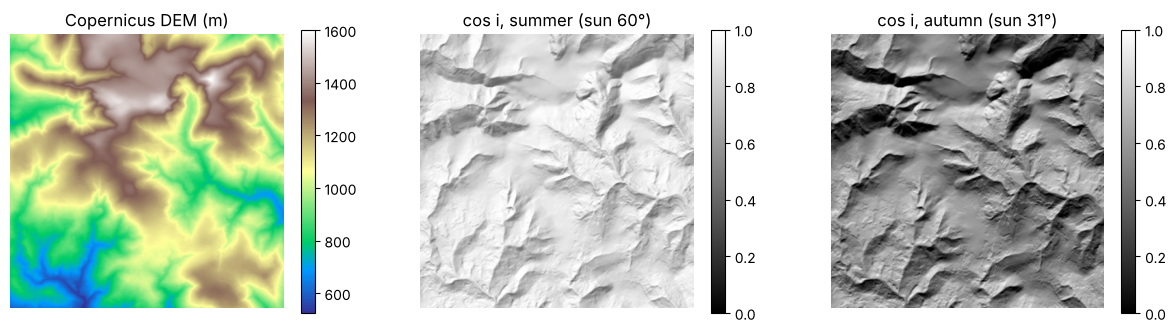

summer: cos i on flat ground 0.86, in the window 1st–99th percentile 0.46 to 0.99, in self-shadow (cos i < 0) 0.0% of pixels
autumn: cos i on flat ground 0.51, in the window 1st–99th percentile -0.02 to 0.86, in self-shadow (cos i < 0) 1.4% of pixels


In [4]:
dzdy, dzdx = np.gradient(dem, 30)                  # rows run south, columns run east
dzdE, dzdN = dzdx, -dzdy
slope = np.arctan(np.hypot(dzdE, dzdN))
aspect = np.arctan2(-dzdE, -dzdN) % (2 * np.pi)    # where the slope faces, clockwise from north
for s in L8.values():
    zs, az = np.radians(90 - s["el"]), np.radians(s["az"])
    s["cosi"] = np.cos(zs) * np.cos(slope) + np.sin(zs) * np.sin(slope) * np.cos(az - aspect)
    s["cosz"] = np.cos(zs)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
im = ax[0].imshow(dem, cmap="terrain"); ax[0].set_title("Copernicus DEM (m)"); fig.colorbar(im, ax=ax[0], shrink=0.8)
for a, (season, s) in zip(ax[1:], L8.items()):
    im = a.imshow(s["cosi"], cmap="gray", vmin=0, vmax=1); a.set_title(f"cos i, {season} (sun {s['el']:.0f}°)"); fig.colorbar(im, ax=a, shrink=0.8)
for a in ax: a.axis("off")
plt.show()
for season, s in L8.items():
    print(f"{season}: cos i on flat ground {s['cosz']:.2f}, in the window 1st–99th percentile {np.percentile(s['cosi'], 1):.2f} to {np.percentile(s['cosi'], 99):.2f}, "
          f"in self-shadow (cos i < 0) {np.mean(s['cosi'] < 0):.1%} of pixels")

> **✏️ Task 1.** Compare the cos i maps in summer and in autumn. Why do south- and north-facing slopes differ much more in autumn, and how many pixels are in self-shadow? Why does the TOA reflectance formula from the visual's notebook (dividing by the sine of the sun elevation) not give the true surface reflectance on a slope?

*Your answer:* 

## 3. How strongly the terrain changes forest reflectance

We take forest pixels according to WorldCover and fit a line ρ = m · cos i + b. If the slope were lit only by direct sun and the forest reflected equally in all directions, reflectance would be proportional to cos i and the offset b would be zero. The ratio C = b/m is the basis of the C-correction (Teillet et al. 1982).

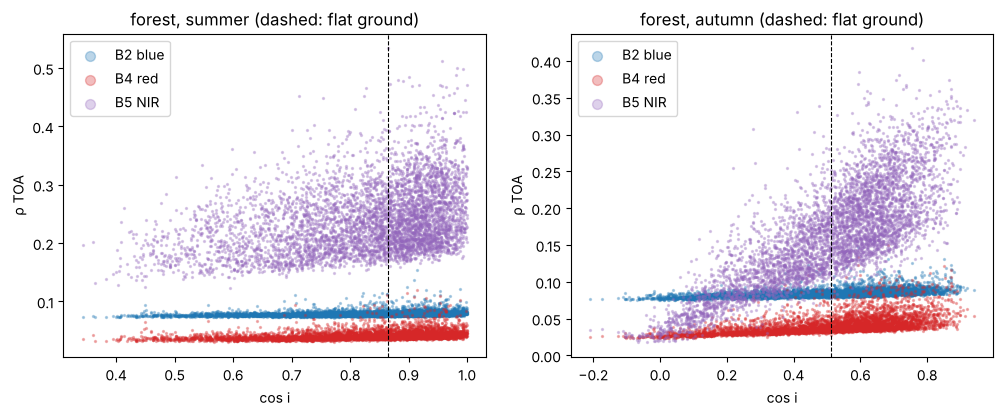

r  slope m  offset b  C = b/m
season band                                       
summer B2 blue   0.278    0.009     0.072    7.777
       B3 green  0.339    0.020     0.048    2.429
       B4 red    0.316    0.019     0.026    1.384
       B5 NIR    0.342    0.146     0.117    0.804
       B6 SWIR1  0.366    0.095     0.019    0.201
       B7 SWIR2  0.338    0.048     0.004    0.092
autumn B2 blue   0.499    0.013     0.078    6.030
       B3 green  0.631    0.029     0.044    1.510
       B4 red    0.535    0.032     0.025    0.795
       B5 NIR    0.795    0.252     0.036    0.144
       B6 SWIR1  0.614    0.127    -0.000   -0.003
       B7 SWIR2  0.548    0.062    -0.002   -0.030

In [5]:
forest = (wc == 10) & (slope > np.radians(2))
rows, rng = [], np.random.default_rng(0)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, (season, s) in zip(ax, L8.items()):
    f = forest & s["ok"]
    sel = rng.choice(np.flatnonzero(f.ravel()), 5000, replace=False)
    for b, col in [(2, "tab:blue"), (4, "tab:red"), (5, "tab:purple")]:
        a.scatter(s["cosi"].ravel()[sel], s["toa"][b].ravel()[sel], s=2, alpha=0.3, c=col, label=f"B{b} {BANDS[b]}")
    a.axvline(s["cosz"], color="k", lw=0.8, ls="--")
    a.set(xlabel="cos i", ylabel="ρ TOA", title=f"forest, {season} (dashed: flat ground)"); a.legend(markerscale=5)
    for b in BANDS:
        k, q = np.polyfit(s["cosi"][f], s["toa"][b][f], 1)
        rows.append({"season": season, "band": f"B{b} {BANDS[b]}", "r": np.corrcoef(s["cosi"][f], s["toa"][b][f])[0, 1],
                     "slope m": k, "offset b": q, "C = b/m": q / k})
plt.show()
pd.DataFrame(rows).set_index(["season", "band"]).round(3)

> **✏️ Task 2.** In which band and season is the relationship with cos i strongest? Why does the blue band have a large C, i.e. a large offset compared with the slope, and SWIR almost zero? Relate it to the share of diffuse skylight at different wavelengths.

*Your answer:* 

## 4. Five corrections

The cosine correction ρ · cos θ_s / cos i assumes direct light only. The C-correction adds C to both numerator and denominator, the Minnaert correction ρ · (cos θ_s / cos i)^k estimates the exponent k from the data, and SCS+C (Soenen et al. 2005) accounts for trees growing vertically, not perpendicular to the slope. We assess the correlation with cos i after correction, the spread of forest reflectance and the ratio of medians on steep south- and north-facing slopes (for the same forest it should be close to 1).

In [6]:
COSI_MIN = 0.15        # ◀ parameter: pixels with cos i below this value are not corrected (nearly in shadow)

def correct(rho, cosi, cosz, slope, method, f):
    """Topographic correction of reflectance rho; method parameters (C, k) are estimated on pixels f."""
    if method == "none":
        return rho
    if method == "cosine":
        return rho * cosz / cosi
    if method == "C":
        m, b = np.polyfit(cosi[f], rho[f], 1)
        return rho * (cosz + b / m) / (cosi + b / m)
    if method == "Minnaert":
        k = np.polyfit(np.log(cosi[f] / cosz), np.log(rho[f]), 1)[0]
        return rho * (cosz / cosi) ** k
    if method == "SCS+C":
        m, b = np.polyfit(cosi[f], rho[f], 1)
        return rho * (np.cos(slope) * cosz + b / m) / (cosi + b / m)
    raise ValueError(method)

METHODS = ["none", "cosine", "C", "Minnaert", "SCS+C"]
sunny, shady = (np.degrees(aspect) > 135) & (np.degrees(aspect) < 225), (np.degrees(aspect) < 45) | (np.degrees(aspect) > 315)
rows = []
for season, s in L8.items():
    f = forest & s["ok"] & (s["cosi"] > COSI_MIN)
    steep = f & (slope > np.radians(15))
    for b in [2, 4, 5, 6]:
        for meth in METHODS:
            c = correct(s["toa"][b], s["cosi"], s["cosz"], slope, meth, f)
            q25, q50, q75 = np.percentile(c[f], [25, 50, 75])
            rows.append({"season": season, "band": f"B{b}", "method": meth, "r with cos i": np.corrcoef(s["cosi"][f], c[f])[0, 1],
                         "spread (IQR/median)": (q75 - q25) / q50,
                         "south/north slopes": np.median(c[steep & sunny]) / np.median(c[steep & shady])})
res = pd.DataFrame(rows).set_index(["season", "band", "method"])
res.round(3)

r with cos i  spread (IQR/median)  south/north slopes
season band method                                                         
summer B2   none             0.278                0.051               1.039
            cosine          -0.934                0.212               0.706
            C               -0.001                0.047               1.002
            Minnaert         0.014                0.048               1.004
            SCS+C            0.038                0.047               1.004
       B4   none             0.316                0.170               1.148
            cosine          -0.585                0.249               0.769
            C               -0.006                0.162               0.991
            Minnaert         0.024                0.161               1.004
            SCS+C            0.041                0.156               0.997
       B5   none             0.342                0.324               1.223
            cosine          -0.413                0.337               0.804
            C               -0.005                0.319               1.005
            Minnaert         0.010                0.319               1.012
            SCS+C            0.045                0.314               1.013
       B6   none             0.366                0.480               1.386
            cosine          -0.144                0.454               0.900
            C               -0.017                0.449               0.988
            Minnaert         0.014                0.450               1.012
            SCS+C            0.041                0.446               1.000
autumn B2   none             0.428                0.066               1.074
            cosine          -0.893                0.485               0.339
            C               -0.002                0.058               0.993
            Minnaert         0.041                0.059               0.996
            SCS+C           -0.008                0.057               0.991
       B4   none             0.469                0.312               1.455
            cosine          -0.699                0.457               0.446
            C               -0.012                0.258               0.951
            Minnaert         0.054                0.265               0.981
            SCS+C           -0.019                0.252               0.947
       B5   none             0.724                0.490               2.445
            cosine          -0.381                0.359               0.762
            C               -0.008                0.352               1.053
            Minnaert        -0.002                0.353               1.041
            SCS+C           -0.020                0.352               1.034
       B6   none             0.554                0.785               3.379
            cosine           0.031                0.602               1.054
            C               -0.057                0.603               0.913
            Minnaert         0.010                0.601               1.020
            SCS+C           -0.063                0.587               0.896

> **✏️ Task 3.** Which method overcorrects (negative r, south/north ratio below 1) and why most in the blue band and in autumn? Why does r come out almost exactly zero for C, Minnaert and SCS+C, and why does that alone not prove the correction works? Suggest a fairer check (e.g. estimating the parameters on one half of the window and assessing on the other).

*Your answer:* 

## 5. Maps and the vegetation index

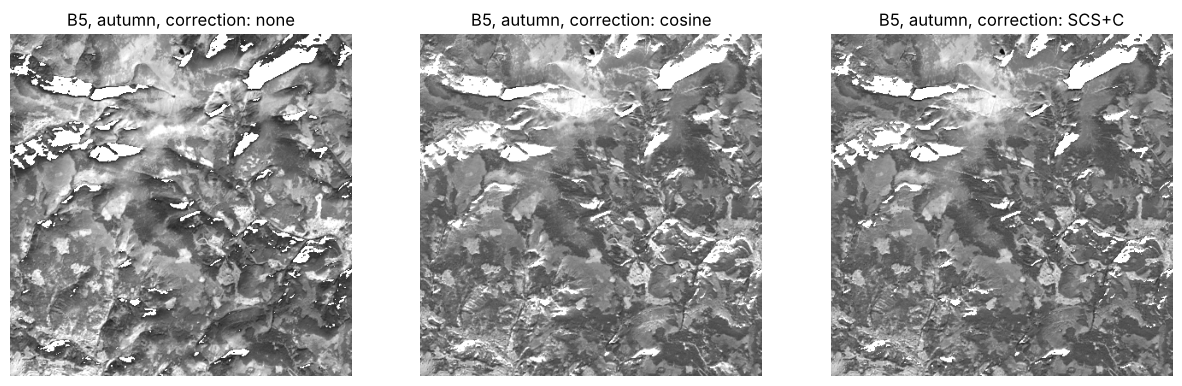

summer: correlation with cos i in forest: NIR 0.34, red 0.32, NDVI 0.13
autumn: correlation with cos i in forest: NIR 0.79, red 0.53, NDVI 0.75


In [7]:
SHOW, BAND = "autumn", 5           # ◀ parameter: season and band for the maps
s = L8[SHOW]
f = forest & s["ok"] & (s["cosi"] > COSI_MIN)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
for a, meth in zip(ax, ["none", "cosine", "SCS+C"]):
    c = np.where(s["cosi"] > COSI_MIN, correct(s["toa"][BAND], s["cosi"], s["cosz"], slope, meth, f), np.nan)
    a.imshow(c, cmap="gray", vmin=0, vmax=np.nanpercentile(s["toa"][BAND], 99)); a.set_title(f"B{BAND}, {SHOW}, correction: {meth}"); a.axis("off")
plt.show()
ndvi = {season: (v["toa"][5] - v["toa"][4]) / (v["toa"][5] + v["toa"][4]) for season, v in L8.items()}
for season, v in L8.items():
    fs = forest & v["ok"]
    print(f"{season}: correlation with cos i in forest: NIR {np.corrcoef(v['cosi'][fs], v['toa'][5][fs])[0, 1]:.2f}, "
          f"red {np.corrcoef(v['cosi'][fs], v['toa'][4][fs])[0, 1]:.2f}, NDVI {np.corrcoef(v['cosi'][fs], ndvi[season][fs])[0, 1]:.2f}")

> **✏️ Task 4.** Where do errors remain in the corrected map (steep north-facing slopes, places below `COSI_MIN`)? Set `COSI_MIN` to 0.05 and 0.3 and describe the difference. Why does the cosine correction turn shaded slopes into the brightest places in the scene?

*Your answer:* 

> **✏️ Task 5.** In summer NDVI hardly correlates with cos i, in autumn it does. Why does a ratio index cancel the terrain effect only when the effect is purely multiplicative? Which two differences between red and NIR (share of diffuse light from step 3, path radiance) spoil this at low sun?

*Your answer:* 

> **✏️ Extension (optional).** Move the window to the Šumava mountains (the DEM and WorldCover tiles then have to change, and the Landsat scenes must cover the new place) or use grassland (`wc == 30`) instead of forest. Do the C and k parameters come out similar?

*Your answer:* 

---
### Data sources and references

- Landsat 8 OLI Collection 1 Level-1, U.S. Geological Survey; Google Cloud public archive (`gcp-public-data-landsat`). USGS data have no use restrictions, attribution requested.
- Copernicus DEM GLO-30: produced using Copernicus WorldDEM-30 © DLR e.V. 2010-2014 and © Airbus Defence and Space GmbH 2014-2018 provided under COPERNICUS by the European Union and ESA; all rights reserved. AWS Open Data registry (`copernicus-dem-30m`).
- Zanaga, D. et al. (2022). *ESA WorldCover 10 m 2021 v200*. https://doi.org/10.5281/zenodo.7254221 (CC BY 4.0).
- Teillet, P. M., Guindon, B., Goodenough, D. G. (1982). On the slope-aspect correction of multispectral scanner data. *Canadian Journal of Remote Sensing* 8(2), 84–106.
- Minnaert, M. (1941). The reciprocity principle in lunar photometry. *Astrophysical Journal* 93, 403–410.
- Soenen, S. A., Peddle, D. R., Coburn, C. A. (2005). SCS+C: a modified sun-canopy-sensor topographic correction in forested terrain. *IEEE Transactions on Geoscience and Remote Sensing* 43, 2148–2159. https://doi.org/10.1109/TGRS.2005.852480

### How to cite

OpenSkyLab (2026). From DN to reflectance, advanced: topographic correction in the Krkonoše mountains [notebook, teaching resource], version 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/dn_to_reflectance_pro_en.ipynb. Licence CC BY 4.0.

Notebook text and code: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data are under their providers' licences (see above).

*This resource was developed by the OpenSkyLab team with the assistance of the generative AI Claude (Anthropic), used for drafting code and text. The authors are responsible for the content.*